<a href="https://colab.research.google.com/github/MyTeachers123/genai-course/blob/main/week2/homework/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2 Homework - Diffusion: Schedules, Conditioning, and Latency
**COM SCI-X 455 - Week 2**

Run on a Colab **T4 GPU** (Runtime -> Change runtime type -> T4 GPU).

* **Part 1** - the Lab 2 U-Net trained on FashionMNIST with three noise schedules, sample grids and FID.
* **Part 2** - class-conditional U-Net with classifier-free guidance (CFG) and a guidance-scale sweep.
* **Part 3** - latency memo, written separately in `memo.md`.

The U-Net, samplers and FID code are the same as in `week2/lab2.ipynb`. The only architecture change is in
Part 2, where a class embedding is added to the time embedding.

**Time budget on a T4 (approx.):** Part 1 about 2.5-3 h (3 x 40 epochs + FID), Part 2 about 40 min.
Checkpoints are written to Google Drive, so if Colab disconnects, run all cells again and training continues
from the last finished epoch.

## Setup

In [4]:
!pip install pytorch-fid --quiet

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoints -> /content/drive/MyDrive/genai-week2-hw/checkpoints | images -> /content/drive/MyDrive/genai-week2-hw/images
Device: Tesla T4
Train: 60000 | image shape: torch.Size([1, 32, 32])


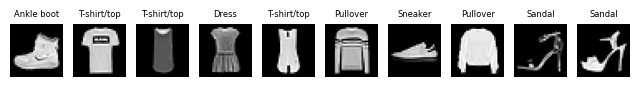

In [5]:
import os, time, math, json
import torch, torch.nn as nn, torch.nn.functional as F, numpy as np, matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# ---- Where checkpoints live: Google Drive on Colab (survives disconnects), local folder otherwise ----
RUN_DIR = '.'
try:
    from google.colab import drive
    drive.mount('/content/drive')
    RUN_DIR = '/content/drive/MyDrive/genai-week2-hw'
except ImportError:
    pass
CKPT_DIR = os.path.join(RUN_DIR, 'checkpoints')
IMG = os.path.join(RUN_DIR, 'images')            # images also on Drive, so they survive a disconnect
os.makedirs(CKPT_DIR, exist_ok=True); os.makedirs(IMG, exist_ok=True)
print('Checkpoints ->', CKPT_DIR, '| images ->', IMG)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU - switch the runtime to T4 GPU')
SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED)

# ---- Settings (FAST_DEV only for a quick code check; keep False for the real run) ----
FAST_DEV = False
EPOCHS = 2 if FAST_DEV else 40            # Part 1: 40 epochs per variant
COND_EPOCHS = 2 if FAST_DEV else 30       # Part 2
BATCH = 128
LR = 2e-4
T = 50 if FAST_DEV else 1000
SNAP_EPOCHS = [1, 2] if FAST_DEV else [10, 20, 30, 40]
FID_EPOCHS = [2] if FAST_DEV else [20, 40]
N_FID = 100 if FAST_DEV else 1000
USE_AMP = DEVICE == 'cuda'                # fp16 mixed precision: about 1.5-2x faster on a T4

CLASSES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
           'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

transform = transforms.Compose([
    transforms.Pad(2),                      # 28x28 -> 32x32 (same fix as the lab)
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),   # [-1, 1]
])
train_data = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_data = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)
if FAST_DEV:
    train_data = torch.utils.data.Subset(train_data, range(512))
loader = DataLoader(train_data, batch_size=BATCH, shuffle=True, num_workers=2, drop_last=True)
print('Train:', len(train_data), '| image shape:', train_data[0][0].shape)

RESULTS_PATH = os.path.join(RUN_DIR, 'results.json')
RESULTS = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}
def save_results():
    json.dump(RESULTS, open(RESULTS_PATH, 'w'), indent=2)
    json.dump(RESULTS, open('results.json', 'w'), indent=2)

def to01(x): return ((x.clamp(-1, 1) + 1) / 2).cpu()

def grid_image(imgs, nrow):
    """(N,1,32,32) in [-1,1] -> one (rows*32, nrow*32) array."""
    x = to01(imgs)[:, 0]; n = x.size(0); nr = math.ceil(n / nrow)
    pad = torch.ones(nr * nrow - n, 32, 32)
    x = torch.cat([x, pad]).view(nr, nrow, 32, 32).permute(0, 2, 1, 3).reshape(nr * 32, nrow * 32)
    return x.numpy()

def save_grid(imgs, nrow, title, path, size=4):
    plt.figure(figsize=(size, size * math.ceil(len(imgs) / nrow) / nrow + 0.3))
    plt.imshow(grid_image(imgs, nrow), cmap='gray', vmin=0, vmax=1); plt.axis('off'); plt.title(title, fontsize=9)
    plt.tight_layout(); plt.savefig(path, dpi=150, bbox_inches='tight'); plt.show()

plt.figure(figsize=(8, 1.2))
for i in range(10):
    x, y = train_data[i]
    plt.subplot(1, 10, i + 1); plt.imshow(to01(x)[0], cmap='gray'); plt.axis('off'); plt.title(CLASSES[y], fontsize=6)
plt.show()

## Noise schedules
Variant A: linear, beta 1e-4 -> 0.02. Variant B: cosine, s = 0.008 (lab). Variant C: cosine, s = 0.04.

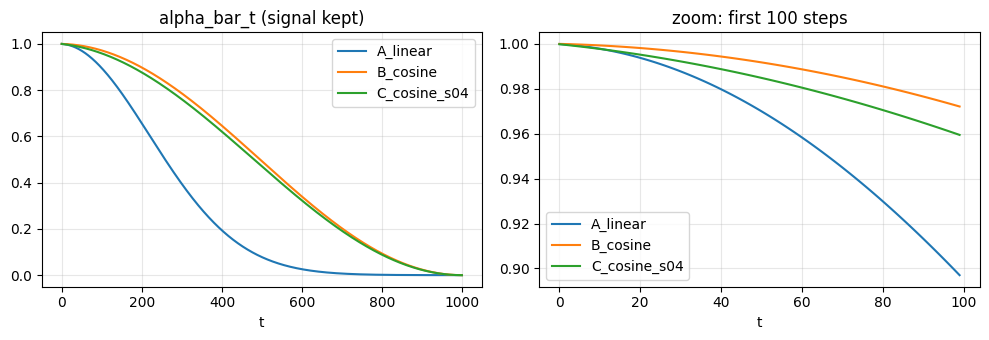

A_linear       alpha_bar at t=T/10: 0.895 | t=T/4: 0.521 | t=T/2: 0.078
B_cosine       alpha_bar at t=T/10: 0.972 | t=T/4: 0.846 | t=T/2: 0.492
C_cosine_s04   alpha_bar at t=T/10: 0.959 | t=T/4: 0.822 | t=T/2: 0.470


In [6]:
def linear_schedule(T=1000, beta_start=1e-4, beta_end=0.02):
    return torch.linspace(beta_start, beta_end, T)

def cosine_schedule(T=1000, s=0.008):
    steps = torch.arange(T + 1, dtype=torch.float32)
    f = torch.cos(((steps / T + s) / (1 + s)) * torch.pi / 2) ** 2
    alphas_bar = f / f[0]
    betas = 1 - (alphas_bar[1:] / alphas_bar[:-1])
    return torch.clamp(betas, 0, 0.999)

class NoiseSchedule:
    def __init__(self, kind='linear', T=1000, device=DEVICE, **kw):
        self.kind, self.T = kind, T
        betas = linear_schedule(T, **kw) if kind == 'linear' else cosine_schedule(T, **kw)
        self.betas = betas.to(device)
        self.alphas = 1 - self.betas
        self.alphas_cumprod = torch.cumprod(self.alphas, 0)

    def q_sample(self, x0, t, noise=None):
        """Returns (x_t, noise) - the SAME noise is used as the training target."""
        if noise is None:
            noise = torch.randn_like(x0)
        ab = self.alphas_cumprod[t].view(-1, 1, 1, 1)
        return ab.sqrt() * x0 + (1 - ab).sqrt() * noise, noise

VARIANTS = {
    'A_linear':     NoiseSchedule('linear', T, beta_start=1e-4, beta_end=0.02),
    'B_cosine':     NoiseSchedule('cosine', T, s=0.008),
    'C_cosine_s04': NoiseSchedule('cosine', T, s=0.04),
}

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for k, s in VARIANTS.items():
    ax[0].plot(s.alphas_cumprod.cpu(), label=k)
    ax[1].plot(s.alphas_cumprod.cpu()[: T // 10], label=k)
ax[0].set_title('alpha_bar_t (signal kept)'); ax[1].set_title(f'zoom: first {T // 10} steps')
for a in ax: a.set_xlabel('t'); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig(f'{IMG}/schedules_alpha_bar.png', dpi=150); plt.show()
for k, s in VARIANTS.items():
    ab = s.alphas_cumprod.cpu()
    print(f'{k:<14} alpha_bar at t=T/10: {ab[T // 10]:.3f} | t=T/4: {ab[T // 4]:.3f} | t=T/2: {ab[T // 2]:.3f}')

## U-Net (same as the lab) + optional class conditioning
`num_classes=None` gives exactly the lab U-Net (Part 1). With `num_classes=10` the model gets an
`nn.Embedding(11, 128)`: index 0-9 are the classes and index 10 is the **null / unconditional** token used for CFG.
The class embedding is added to the time embedding, so every ResBlock sees both "how noisy" and "which class".

In [7]:
class SinusoidalTimeEmb(nn.Module):
    def __init__(self, dim=128):
        super().__init__()
        self.dim = dim
        self.mlp = nn.Sequential(nn.Linear(dim, dim * 4), nn.SiLU(), nn.Linear(dim * 4, dim))
    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000.0) * torch.arange(half, device=t.device) / (half - 1))
        args = t[:, None].float() * freqs[None]
        return self.mlp(torch.cat([torch.sin(args), torch.cos(args)], dim=-1))

class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_dim=128):
        super().__init__()
        self.norm1, self.conv1 = nn.GroupNorm(8, in_ch), nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.time_proj = nn.Linear(time_dim, out_ch)
        self.norm2, self.conv2 = nn.GroupNorm(8, out_ch), nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()
    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_proj(emb)[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)

class SelfAttention(nn.Module):
    def __init__(self, ch, heads=4):
        super().__init__()
        self.norm = nn.GroupNorm(8, ch)
        self.attn = nn.MultiheadAttention(ch, heads, batch_first=True)
    def forward(self, x):
        b, c, h, w = x.shape
        q = self.norm(x).flatten(2).transpose(1, 2)
        out, _ = self.attn(q, q, q)
        return x + out.transpose(1, 2).reshape(b, c, h, w)

class UNet(nn.Module):
    def __init__(self, channels=(32, 64, 128), time_dim=128, num_classes=None):
        super().__init__()
        self.num_classes = num_classes
        self.time_embed = SinusoidalTimeEmb(time_dim)
        if num_classes is not None:
            self.class_embed = nn.Embedding(num_classes + 1, time_dim)   # last index = null token
        self.init_conv = nn.Conv2d(1, channels[0], 3, padding=1)
        self.down_blocks, self.downsample = nn.ModuleList(), nn.ModuleList()
        ch_in = channels[0]
        for ch in channels:
            self.down_blocks.append(ResBlock(ch_in, ch, time_dim))
            self.downsample.append(nn.Conv2d(ch, ch, 4, 2, 1))
            ch_in = ch
        mid = channels[-1] * 2
        self.mid1 = ResBlock(ch_in, mid, time_dim)
        self.mid_attn = SelfAttention(mid)
        self.mid2 = ResBlock(mid, mid, time_dim)
        self.upsample, self.up_blocks = nn.ModuleList(), nn.ModuleList()
        ch_in = mid
        for ch in reversed(channels):
            self.upsample.append(nn.ConvTranspose2d(ch_in, ch_in, 4, 2, 1))
            self.up_blocks.append(ResBlock(ch_in + ch, ch, time_dim))
            ch_in = ch
        self.out = nn.Sequential(nn.GroupNorm(8, channels[0]), nn.SiLU(), nn.Conv2d(channels[0], 1, 3, padding=1))

    def forward(self, x, t, y=None):
        emb = self.time_embed(t)
        if self.num_classes is not None:
            if y is None:                                               # no label -> null token
                y = torch.full((x.size(0),), self.num_classes, device=x.device, dtype=torch.long)
            emb = emb + self.class_embed(y)                             # time + class, same dimension
        x = self.init_conv(x)
        skips = []
        for block, down in zip(self.down_blocks, self.downsample):
            x = block(x, emb); skips.append(x)
            x = down(x)
        x = self.mid2(self.mid_attn(self.mid1(x, emb)), emb)
        for up, block, skip in zip(self.upsample, self.up_blocks, reversed(skips)):
            x = up(x)
            x = block(torch.cat([x, skip], dim=1), emb)
        return self.out(x)

with torch.no_grad():
    m = UNet().to(DEVICE)
    print('Unconditional params:', sum(p.numel() for p in m.parameters()))
    mc = UNet(num_classes=10).to(DEVICE)
    print('Conditional params:  ', sum(p.numel() for p in mc.parameters()), '(+ 11 x 128 class embedding)')
    print('Shape check:', mc(torch.randn(2, 1, 32, 32, device=DEVICE), torch.tensor([0, T - 1], device=DEVICE),
                             torch.tensor([0, 7], device=DEVICE)).shape)
del m, mc

Unconditional params: 5488737
Conditional params:   5490145 (+ 11 x 128 class embedding)
Shape check: torch.Size([2, 1, 32, 32])


## Samplers
`ddpm_sample` works for both models. When `y` is given and `w` is set, every step runs the model twice
(conditional and unconditional - done as one batch of 2B) and blends:

**eps = eps_uncond + w * (eps_cond - eps_uncond)**

w = 1 is plain conditional sampling (no extra guidance); larger w pushes harder toward the class.

In [8]:
def predict_eps(model, x, tt, y=None, w=None):
    if y is None or w is None:
        return model(x, tt, y) if model.num_classes is not None else model(x, tt)
    null = torch.full_like(y, model.num_classes)
    eps_c, eps_u = model(torch.cat([x, x]), torch.cat([tt, tt]), torch.cat([y, null])).chunk(2)
    return eps_u + w * (eps_c - eps_u)

@torch.no_grad()
def ddpm_sample(model, sched, x_T, y=None, w=None):
    model.eval(); x = x_T.clone()
    for t in reversed(range(sched.T)):
        tt = torch.full((x.size(0),), t, device=x.device, dtype=torch.long)
        with torch.autocast('cuda', dtype=torch.float16, enabled=USE_AMP):
            eps = predict_eps(model, x, tt, y, w)
        eps = eps.float()
        beta, alpha, ab = sched.betas[t], sched.alphas[t], sched.alphas_cumprod[t]
        x = (x - beta / (1 - ab).sqrt() * eps) / alpha.sqrt()
        if t > 0:
            x = x + beta.sqrt() * torch.randn_like(x)
    return x.clamp(-1, 1)

## FID setup
1,000 generated samples vs 1,000 real FashionMNIST **test** images, Inception-v3 pool features (pytorch-fid).
A real-vs-real score is printed as the practical floor at this sample size.

In [9]:
from pytorch_fid.inception import InceptionV3
from scipy import linalg

def calculate_frechet_distance(mu1, sigma1, mu2, sigma2, eps=1e-6):
    """Same formula as pytorch_fid; written here because new SciPy removed sqrtm(disp=...)."""
    diff = mu1 - mu2
    covmean = linalg.sqrtm(sigma1.dot(sigma2))
    if not np.isfinite(covmean).all():
        offset = np.eye(sigma1.shape[0]) * eps
        covmean = linalg.sqrtm((sigma1 + offset).dot(sigma2 + offset))
    covmean = covmean.real
    return diff.dot(diff) + np.trace(sigma1) + np.trace(sigma2) - 2 * np.trace(covmean)
inception = InceptionV3([InceptionV3.BLOCK_INDEX_BY_DIM[2048]]).to(DEVICE).eval()

@torch.no_grad()
def stats(imgs01, bs=100):
    f = np.concatenate([inception(imgs01[i:i+bs].to(DEVICE).repeat(1, 3, 1, 1))[0].flatten(1).cpu().numpy()
                        for i in range(0, len(imgs01), bs)])
    return f.mean(0), np.cov(f, rowvar=False)

real_test = torch.stack([test_data[i][0] for i in range(N_FID)])
mu_r, sig_r = stats(to01(real_test))
def fid(x): mu, sig = stats(to01(x)); return float(calculate_frechet_distance(mu, sig, mu_r, sig_r))

@torch.no_grad()
def generate(model, sched, n=N_FID, bs=500, seed=11):
    g = torch.Generator().manual_seed(seed); bs = min(bs, n); out = []
    for _ in range(n // bs):
        out.append(ddpm_sample(model, sched, torch.randn(bs, 1, 32, 32, generator=g).to(DEVICE)).cpu())
    return torch.cat(out)

if 'fid_floor' not in RESULTS:
    real_train = torch.stack([train_data[i][0] for i in range(N_FID)])
    RESULTS['fid_floor'] = fid(real_train); save_results()
print(f"Real train vs real test (floor): {RESULTS['fid_floor']:.2f}")

Downloading: "https://github.com/mseitzer/pytorch-fid/releases/download/fid_weights/pt_inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/pt_inception-2015-12-05-6726825d.pth


100%|██████████| 91.2M/91.2M [00:00<00:00, 184MB/s]


Real train vs real test (floor): 22.10


## Part 1 - Train the three variants (40 epochs each)
Every snapshot epoch (10/20/30/40) saves a 5x5 DDPM-1000 grid from the same fixed noise.
FID is measured at epochs 20 and 40 **inside** the loop, so the epoch-20 number comes from the epoch-20 weights.
Training time excludes sampling and FID.

[A_linear] epoch  1 | loss 0.0807 | train   0.5 min
[A_linear] epoch  2 | loss 0.0414 | train   1.0 min
[A_linear] epoch  3 | loss 0.0379 | train   1.5 min
[A_linear] epoch  4 | loss 0.0353 | train   2.0 min
[A_linear] epoch  5 | loss 0.0341 | train   2.5 min
[A_linear] epoch  6 | loss 0.0328 | train   3.1 min
[A_linear] epoch  7 | loss 0.0332 | train   3.6 min
[A_linear] epoch  8 | loss 0.0323 | train   4.1 min
[A_linear] epoch  9 | loss 0.0315 | train   4.6 min


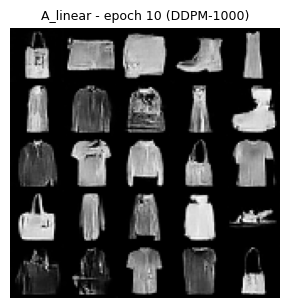

[A_linear] epoch 10 | loss 0.0312 | train   5.1 min | grid saved
[A_linear] epoch 11 | loss 0.0315 | train   5.6 min
[A_linear] epoch 12 | loss 0.0304 | train   6.1 min
[A_linear] epoch 13 | loss 0.0302 | train   6.7 min
[A_linear] epoch 14 | loss 0.0302 | train   7.2 min
[A_linear] epoch 15 | loss 0.0301 | train   7.7 min
[A_linear] epoch 16 | loss 0.0298 | train   8.2 min
[A_linear] epoch 17 | loss 0.0301 | train   8.7 min
[A_linear] epoch 18 | loss 0.0296 | train   9.2 min
[A_linear] epoch 19 | loss 0.0297 | train   9.7 min


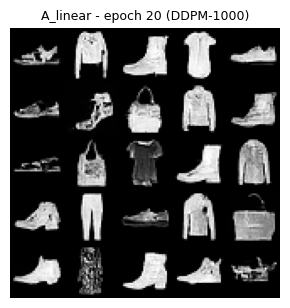

[A_linear] epoch 20 | loss 0.0293 | train  10.2 min | grid saved | FID 41.60
[A_linear] epoch 21 | loss 0.0295 | train  10.8 min
[A_linear] epoch 22 | loss 0.0291 | train  11.3 min
[A_linear] epoch 23 | loss 0.0291 | train  11.8 min
[A_linear] epoch 24 | loss 0.0288 | train  12.3 min
[A_linear] epoch 25 | loss 0.0291 | train  12.8 min
[A_linear] epoch 26 | loss 0.0289 | train  13.3 min
[A_linear] epoch 27 | loss 0.0284 | train  13.8 min
[A_linear] epoch 28 | loss 0.0284 | train  14.3 min
[A_linear] epoch 29 | loss 0.0288 | train  14.8 min


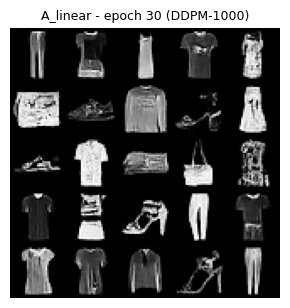

[A_linear] epoch 30 | loss 0.0282 | train  15.3 min | grid saved
[A_linear] epoch 31 | loss 0.0284 | train  15.8 min
[A_linear] epoch 32 | loss 0.0286 | train  16.3 min
[A_linear] epoch 33 | loss 0.0282 | train  16.8 min
[A_linear] epoch 34 | loss 0.0278 | train  17.3 min
[A_linear] epoch 35 | loss 0.0283 | train  17.8 min
[A_linear] epoch 36 | loss 0.0280 | train  18.3 min
[A_linear] epoch 37 | loss 0.0282 | train  18.8 min
[A_linear] epoch 38 | loss 0.0280 | train  19.3 min
[A_linear] epoch 39 | loss 0.0276 | train  19.8 min


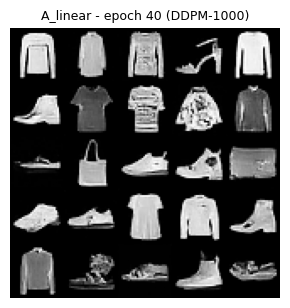

[A_linear] epoch 40 | loss 0.0278 | train  20.3 min | grid saved | FID 36.98
[B_cosine] epoch  1 | loss 0.1234 | train   0.5 min
[B_cosine] epoch  2 | loss 0.0724 | train   1.0 min
[B_cosine] epoch  3 | loss 0.0666 | train   1.5 min
[B_cosine] epoch  4 | loss 0.0629 | train   2.1 min
[B_cosine] epoch  5 | loss 0.0610 | train   2.6 min
[B_cosine] epoch  6 | loss 0.0590 | train   3.1 min
[B_cosine] epoch  7 | loss 0.0593 | train   3.6 min
[B_cosine] epoch  8 | loss 0.0579 | train   4.1 min
[B_cosine] epoch  9 | loss 0.0569 | train   4.6 min


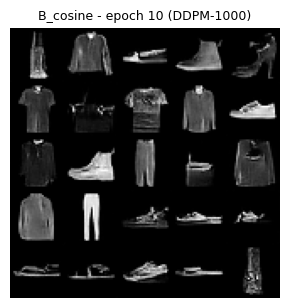

[B_cosine] epoch 10 | loss 0.0563 | train   5.1 min | grid saved
[B_cosine] epoch 11 | loss 0.0564 | train   5.6 min
[B_cosine] epoch 12 | loss 0.0551 | train   6.1 min
[B_cosine] epoch 13 | loss 0.0547 | train   6.6 min
[B_cosine] epoch 14 | loss 0.0544 | train   7.1 min
[B_cosine] epoch 15 | loss 0.0544 | train   7.6 min
[B_cosine] epoch 16 | loss 0.0538 | train   8.1 min
[B_cosine] epoch 17 | loss 0.0542 | train   8.6 min
[B_cosine] epoch 18 | loss 0.0536 | train   9.1 min
[B_cosine] epoch 19 | loss 0.0536 | train   9.7 min


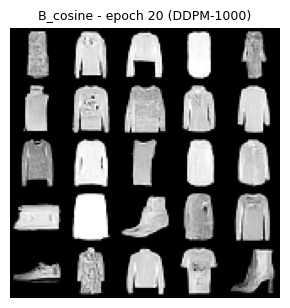

[B_cosine] epoch 20 | loss 0.0530 | train  10.2 min | grid saved | FID 43.67
[B_cosine] epoch 21 | loss 0.0533 | train  10.7 min
[B_cosine] epoch 22 | loss 0.0526 | train  11.2 min
[B_cosine] epoch 23 | loss 0.0526 | train  11.7 min
[B_cosine] epoch 24 | loss 0.0520 | train  12.3 min
[B_cosine] epoch 25 | loss 0.0527 | train  12.8 min
[B_cosine] epoch 26 | loss 0.0522 | train  13.3 min
[B_cosine] epoch 27 | loss 0.0517 | train  13.8 min
[B_cosine] epoch 28 | loss 0.0515 | train  14.3 min
[B_cosine] epoch 29 | loss 0.0520 | train  14.8 min


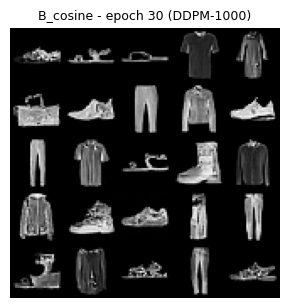

[B_cosine] epoch 30 | loss 0.0512 | train  15.3 min | grid saved
[B_cosine] epoch 31 | loss 0.0515 | train  15.8 min
[B_cosine] epoch 32 | loss 0.0517 | train  16.3 min
[B_cosine] epoch 33 | loss 0.0511 | train  16.8 min
[B_cosine] epoch 34 | loss 0.0506 | train  17.3 min
[B_cosine] epoch 35 | loss 0.0512 | train  17.8 min
[B_cosine] epoch 36 | loss 0.0507 | train  18.3 min
[B_cosine] epoch 37 | loss 0.0511 | train  18.8 min
[B_cosine] epoch 38 | loss 0.0508 | train  19.3 min
[B_cosine] epoch 39 | loss 0.0503 | train  19.8 min


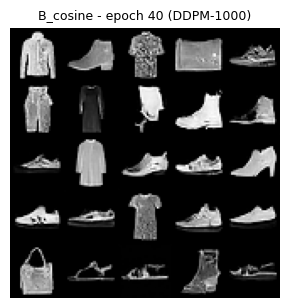

[B_cosine] epoch 40 | loss 0.0506 | train  20.4 min | grid saved | FID 44.55
[C_cosine_s04] epoch  1 | loss 0.1127 | train   0.5 min
[C_cosine_s04] epoch  2 | loss 0.0644 | train   1.0 min
[C_cosine_s04] epoch  3 | loss 0.0593 | train   1.5 min
[C_cosine_s04] epoch  4 | loss 0.0560 | train   2.0 min
[C_cosine_s04] epoch  5 | loss 0.0544 | train   2.5 min
[C_cosine_s04] epoch  6 | loss 0.0526 | train   3.0 min
[C_cosine_s04] epoch  7 | loss 0.0528 | train   3.5 min
[C_cosine_s04] epoch  8 | loss 0.0515 | train   4.0 min
[C_cosine_s04] epoch  9 | loss 0.0507 | train   4.6 min


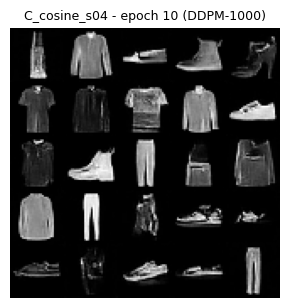

[C_cosine_s04] epoch 10 | loss 0.0502 | train   5.1 min | grid saved
[C_cosine_s04] epoch 11 | loss 0.0503 | train   5.6 min
[C_cosine_s04] epoch 12 | loss 0.0491 | train   6.1 min
[C_cosine_s04] epoch 13 | loss 0.0488 | train   6.6 min
[C_cosine_s04] epoch 14 | loss 0.0485 | train   7.1 min
[C_cosine_s04] epoch 15 | loss 0.0485 | train   7.6 min
[C_cosine_s04] epoch 16 | loss 0.0480 | train   8.1 min
[C_cosine_s04] epoch 17 | loss 0.0483 | train   8.7 min
[C_cosine_s04] epoch 18 | loss 0.0479 | train   9.2 min
[C_cosine_s04] epoch 19 | loss 0.0478 | train   9.7 min


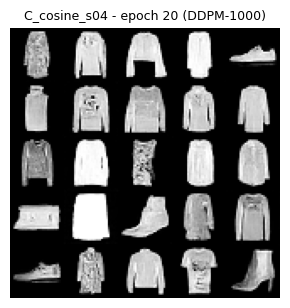

[C_cosine_s04] epoch 20 | loss 0.0473 | train  10.2 min | grid saved | FID 41.74
[C_cosine_s04] epoch 21 | loss 0.0475 | train  10.7 min
[C_cosine_s04] epoch 22 | loss 0.0470 | train  11.2 min
[C_cosine_s04] epoch 23 | loss 0.0469 | train  11.8 min
[C_cosine_s04] epoch 24 | loss 0.0464 | train  12.3 min
[C_cosine_s04] epoch 25 | loss 0.0469 | train  12.8 min
[C_cosine_s04] epoch 26 | loss 0.0466 | train  13.3 min
[C_cosine_s04] epoch 27 | loss 0.0461 | train  13.8 min
[C_cosine_s04] epoch 28 | loss 0.0460 | train  14.4 min
[C_cosine_s04] epoch 29 | loss 0.0463 | train  14.9 min


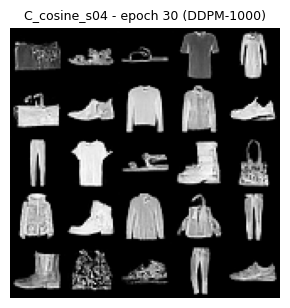

[C_cosine_s04] epoch 30 | loss 0.0456 | train  15.4 min | grid saved
[C_cosine_s04] epoch 31 | loss 0.0458 | train  15.9 min
[C_cosine_s04] epoch 32 | loss 0.0460 | train  16.4 min
[C_cosine_s04] epoch 33 | loss 0.0456 | train  16.9 min
[C_cosine_s04] epoch 34 | loss 0.0451 | train  17.4 min
[C_cosine_s04] epoch 35 | loss 0.0456 | train  17.9 min
[C_cosine_s04] epoch 36 | loss 0.0452 | train  18.5 min
[C_cosine_s04] epoch 37 | loss 0.0455 | train  19.0 min
[C_cosine_s04] epoch 38 | loss 0.0452 | train  19.5 min
[C_cosine_s04] epoch 39 | loss 0.0449 | train  20.0 min


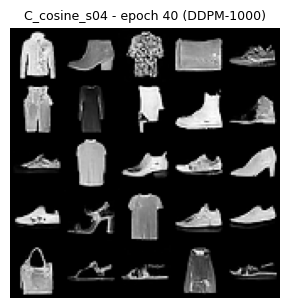

[C_cosine_s04] epoch 40 | loss 0.0451 | train  20.5 min | grid saved | FID 37.82


In [10]:
FIXED_NOISE = torch.randn(25, 1, 32, 32, generator=torch.Generator().manual_seed(123)).to(DEVICE)

def train_variant(name, sched, epochs=EPOCHS):
    torch.manual_seed(SEED)
    model = UNet().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    ckpt = os.path.join(CKPT_DIR, f'unet_{name}.pt')
    state = {'epoch': 0, 'losses': [], 'fid': {}, 'time': 0.0}
    if os.path.exists(ckpt):
        saved = torch.load(ckpt, map_location=DEVICE, weights_only=False)
        model.load_state_dict(saved['model']); opt.load_state_dict(saved['opt']); state = saved['state']
        print(f'[{name}] resuming after epoch {state["epoch"]}')
    for epoch in range(state['epoch'] + 1, epochs + 1):
        model.train(); t0 = time.time(); total = 0.0
        for x0, _ in loader:
            x0 = x0.to(DEVICE)
            t = torch.randint(0, sched.T, (x0.size(0),), device=DEVICE)
            xt, noise = sched.q_sample(x0, t)
            with torch.autocast('cuda', dtype=torch.float16, enabled=USE_AMP):
                loss = F.mse_loss(model(xt, t).float(), noise)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); total += loss.item()
        state['time'] += time.time() - t0
        state['losses'].append(total / len(loader)); state['epoch'] = epoch
        msg = f'[{name}] epoch {epoch:2d} | loss {state["losses"][-1]:.4f} | train {state["time"]/60:5.1f} min'
        if epoch in SNAP_EPOCHS:
            snap = ddpm_sample(model, sched, FIXED_NOISE)
            save_grid(snap, 5, f'{name} - epoch {epoch} (DDPM-{sched.T})', f'{IMG}/part1_{name}_epoch{epoch:02d}.png', size=3)
            msg += ' | grid saved'
        if epoch in FID_EPOCHS:
            state['fid'][epoch] = fid(generate(model, sched))
            msg += f' | FID {state["fid"][epoch]:.2f}'
        print(msg)
        torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'state': state}, ckpt)
    return model, state

MODELS, STATES = {}, {}
for name, sched in VARIANTS.items():
    MODELS[name], STATES[name] = train_variant(name, sched)
    RESULTS.setdefault('part1', {})[name] = {
        'fid': {str(k): v for k, v in STATES[name]['fid'].items()},
        'train_minutes': round(STATES[name]['time'] / 60, 1),
        'final_loss': STATES[name]['losses'][-1]}
    save_results()

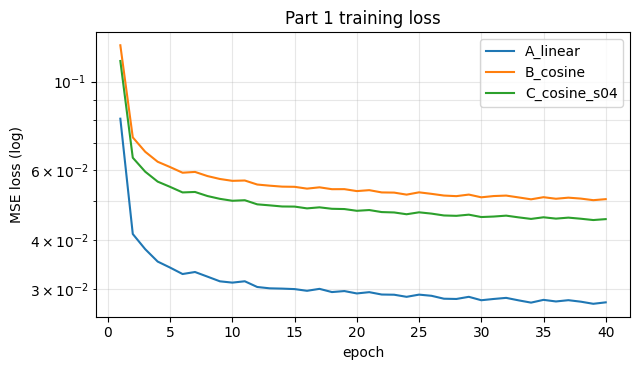

| Variant | Epoch 20 FID | Epoch 40 FID | Training time (min) |
|---|---|---|---|
| A_linear | 41.60 | 36.98 | 20.3 |
| B_cosine | 43.67 | 44.55 | 20.4 |
| C_cosine_s04 | 41.74 | 37.82 | 20.5 |
| real vs real (floor) | 22.10 | 22.10 | - |

Lowest final FID: A_linear


In [11]:
# Loss curves + FID table
plt.figure(figsize=(6.5, 3.8))
for k, s in STATES.items():
    plt.plot(range(1, len(s['losses']) + 1), s['losses'], label=k)
plt.yscale('log'); plt.xlabel('epoch'); plt.ylabel('MSE loss (log)'); plt.title('Part 1 training loss')
plt.legend(); plt.grid(alpha=.3, which='both'); plt.tight_layout(); plt.savefig(f'{IMG}/part1_loss.png', dpi=150); plt.show()

e1, e2 = FID_EPOCHS[0], FID_EPOCHS[-1]
rows = ['| Variant | Epoch %d FID | Epoch %d FID | Training time (min) |' % (e1, e2), '|---|---|---|---|']
for k, s in STATES.items():
    rows.append(f"| {k} | {s['fid'].get(e1, float('nan')):.2f} | {s['fid'].get(e2, float('nan')):.2f} | {s['time'] / 60:.1f} |")
rows.append(f"| real vs real (floor) | {RESULTS['fid_floor']:.2f} | {RESULTS['fid_floor']:.2f} | - |")
table = '\n'.join(rows); print(table)
open(f'{IMG}/part1_fid_table.md', 'w').write(table + '\n')
best = min(STATES, key=lambda k: STATES[k]['fid'].get(e2, 1e9))
RESULTS['part1_best'] = best; save_results()
print('\nLowest final FID:', best)

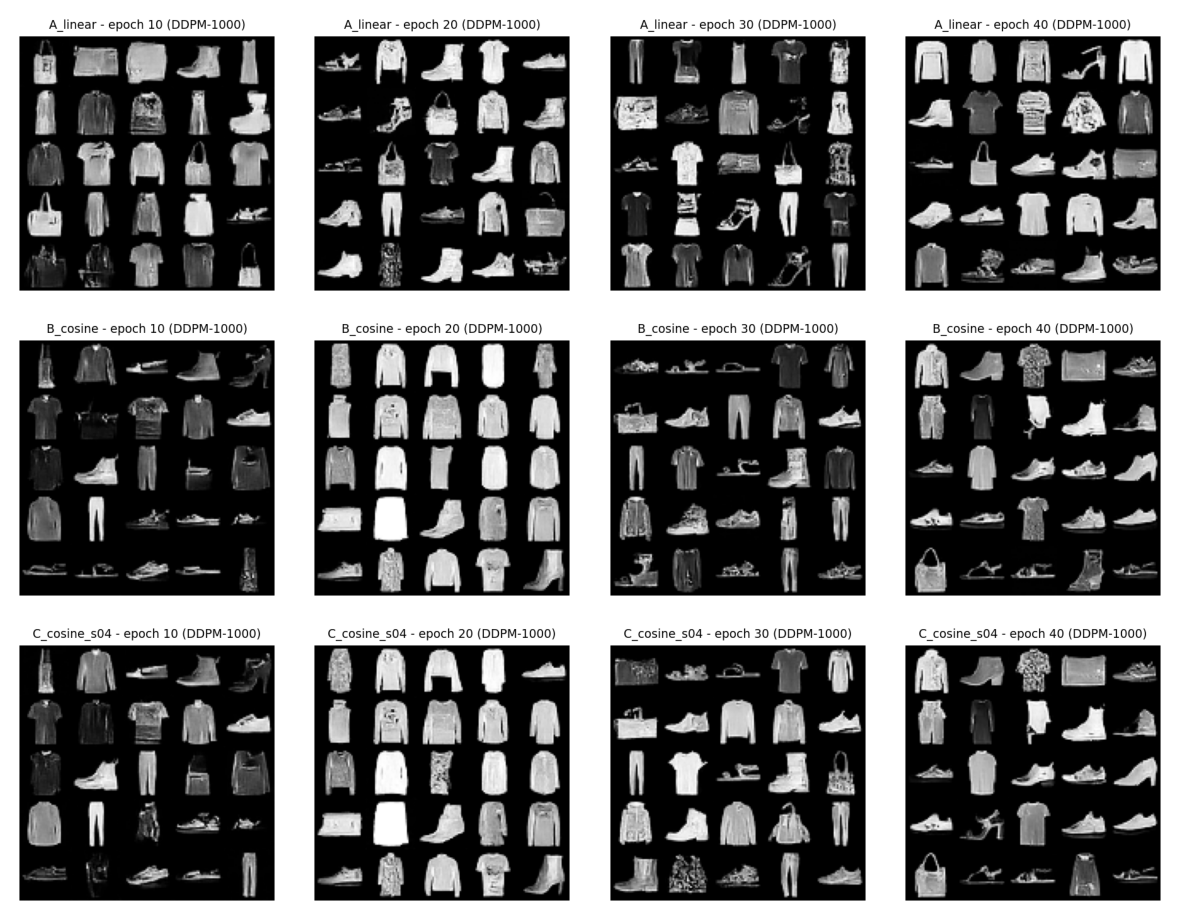

In [12]:
# All 12 grids side by side: rows = variants, columns = epochs
names = list(VARIANTS); eps_ = SNAP_EPOCHS
fig, axes = plt.subplots(len(names), len(eps_), figsize=(3 * len(eps_), 3.1 * len(names)))
for r, n in enumerate(names):
    for c, e in enumerate(eps_):
        p = f'{IMG}/part1_{n}_epoch{e:02d}.png'
        axes[r, c].imshow(plt.imread(p)) if os.path.exists(p) else None; axes[r, c].axis('off')
plt.tight_layout(); plt.savefig(f'{IMG}/part1_all_grids.png', dpi=120, bbox_inches='tight'); plt.show()

### Part 1 analysis (student - about 200 words)
* Which schedule performed best on FashionMNIST (use the FID table and the grids)?
* Does it match your Week 2 MNIST result (lab: linear 17.35, cosine 16.48, floor 15.86)?
* What is different about FashionMNIST (textures, prints, stripes, gray levels inside the object, more
  varied shapes) that makes the schedule choice matter more? Hint: compare how much signal each schedule keeps
  in the early steps (printed under the schedule plot).

Linear (Variant A) performed best on FashionMNIST: FID 36.98 at epoch 40, versus 37.82 for cosine with s = 0.04 (C) and 44.55 for cosine with s = 0.008 (B). The real-vs-real floor at 1,000 samples is 22.10. A and C kept improving from epoch 20 to 40 (by 4.6 and 3.9 points), while B stalled (43.67 -> 44.55). The 0.8-point gap between A and C is within the noise of a 1,000-sample FID, but B is clearly behind. All three variants produce recognisable shirts, trousers, sneakers, sandals and bags by epoch 30. B and C grids look almost identical because they share the starting noise and have similar schedules, so the B-vs-C difference is a distribution-level effect that 25 samples barely show.

This does not match my MNIST lab, where cosine beat linear (16.48 vs 17.35) and the whole spread was under 1 point. On FashionMNIST the spread is 7.6 points, so the schedule matters more here.

My explanation: linear removes signal early (alpha_bar = 0.895 at t = T/10 and 0.078 at T/2), while cosine keeps much more (0.972 and 0.492). With linear, more training timesteps are spent at high noise, where the model learns silhouettes and overall brightness, which is what separates FashionMNIST classes (shirt vs coat vs pullover) and what Inception features pick up at 32x32. Cosine spends more steps near-clean, refining texture that matters less for FID here. Consistent with this, s = 0.04 keeps *less* early signal than s = 0.008 (0.959 vs 0.972) - the opposite of "more early preservation" - and it scored better.

## Part 2 - Class-conditional diffusion with classifier-free guidance
Training is the same loop with one change: the label is passed to the model, and in 15% of samples it is
replaced by the null token (index 10). That single network therefore learns both p(x | class) and p(x).
The schedule is the Part 1 winner (lowest epoch-40 FID).

In [13]:
P_UNCOND = 0.15
COND_SCHED_NAME = RESULTS.get('part1_best', 'B_cosine')
COND_SCHED = VARIANTS[COND_SCHED_NAME]
print('Part 2 schedule:', COND_SCHED_NAME)

def train_conditional(sched, epochs=COND_EPOCHS):
    torch.manual_seed(SEED)
    model = UNet(num_classes=10).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    ckpt = os.path.join(CKPT_DIR, 'unet_conditional.pt')
    state = {'epoch': 0, 'losses': [], 'time': 0.0}
    if os.path.exists(ckpt):
        saved = torch.load(ckpt, map_location=DEVICE, weights_only=False)
        model.load_state_dict(saved['model']); opt.load_state_dict(saved['opt']); state = saved['state']
        print(f'[cond] resuming after epoch {state["epoch"]}')
    for epoch in range(state['epoch'] + 1, epochs + 1):
        model.train(); t0 = time.time(); total = 0.0
        for x0, y in loader:
            x0, y = x0.to(DEVICE), y.to(DEVICE)
            drop = torch.rand(y.size(0), device=DEVICE) < P_UNCOND          # 15% -> unconditional
            y = torch.where(drop, torch.full_like(y, 10), y)
            t = torch.randint(0, sched.T, (x0.size(0),), device=DEVICE)
            xt, noise = sched.q_sample(x0, t)
            with torch.autocast('cuda', dtype=torch.float16, enabled=USE_AMP):
                loss = F.mse_loss(model(xt, t, y).float(), noise)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); total += loss.item()
        state['time'] += time.time() - t0
        state['losses'].append(total / len(loader)); state['epoch'] = epoch
        print(f'[cond] epoch {epoch:2d} | loss {state["losses"][-1]:.4f} | train {state["time"]/60:5.1f} min')
        torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'state': state}, ckpt)
    return model, state

COND_MODEL, COND_STATE = train_conditional(COND_SCHED)
RESULTS['part2'] = {'schedule': COND_SCHED_NAME, 'p_uncond': P_UNCOND,
                    'train_minutes': round(COND_STATE['time'] / 60, 1), 'final_loss': COND_STATE['losses'][-1]}
save_results()

Part 2 schedule: A_linear
[cond] epoch  1 | loss 0.0884 | train   0.5 min
[cond] epoch  2 | loss 0.0427 | train   1.0 min
[cond] epoch  3 | loss 0.0375 | train   1.5 min
[cond] epoch  4 | loss 0.0349 | train   2.1 min
[cond] epoch  5 | loss 0.0343 | train   2.6 min
[cond] epoch  6 | loss 0.0327 | train   3.1 min
[cond] epoch  7 | loss 0.0320 | train   3.6 min
[cond] epoch  8 | loss 0.0322 | train   4.1 min
[cond] epoch  9 | loss 0.0312 | train   4.6 min
[cond] epoch 10 | loss 0.0310 | train   5.1 min
[cond] epoch 11 | loss 0.0306 | train   5.7 min
[cond] epoch 12 | loss 0.0302 | train   6.2 min
[cond] epoch 13 | loss 0.0302 | train   6.7 min
[cond] epoch 14 | loss 0.0296 | train   7.2 min
[cond] epoch 15 | loss 0.0298 | train   7.7 min
[cond] epoch 16 | loss 0.0288 | train   8.2 min
[cond] epoch 17 | loss 0.0290 | train   8.7 min
[cond] epoch 18 | loss 0.0289 | train   9.2 min
[cond] epoch 19 | loss 0.0291 | train   9.7 min
[cond] epoch 20 | loss 0.0294 | train  10.2 min
[cond] epoch 2

### Demonstration: 5 T-shirts (class 0) and 5 Sneakers (class 7), w = 3

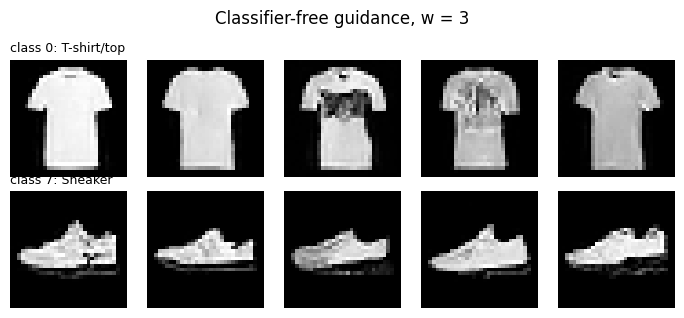

In [14]:
def sample_class(cls, n, w, seed):
    z = torch.randn(n, 1, 32, 32, generator=torch.Generator().manual_seed(seed)).to(DEVICE)
    y = torch.full((n,), cls, device=DEVICE, dtype=torch.long)
    return ddpm_sample(COND_MODEL, COND_SCHED, z, y, w)

demo = torch.cat([sample_class(0, 5, 3.0, seed=1), sample_class(7, 5, 3.0, seed=2)])
fig, axes = plt.subplots(2, 5, figsize=(7, 3.2))
for i, ax in enumerate(axes.reshape(-1)):
    ax.imshow(to01(demo[i])[0], cmap='gray', vmin=0, vmax=1); ax.axis('off')
axes[0, 0].set_title('class 0: T-shirt/top', loc='left', fontsize=9)
axes[1, 0].set_title('class 7: Sneaker', loc='left', fontsize=9)
plt.suptitle('Classifier-free guidance, w = 3'); plt.tight_layout()
plt.savefig(f'{IMG}/part2_demo_tshirt_sneaker.png', dpi=150, bbox_inches='tight'); plt.show()

### Guidance-scale sweep: w = 1, 3, 7, 15
Each row uses the **same starting noise** for all four w values, so only the guidance changes.

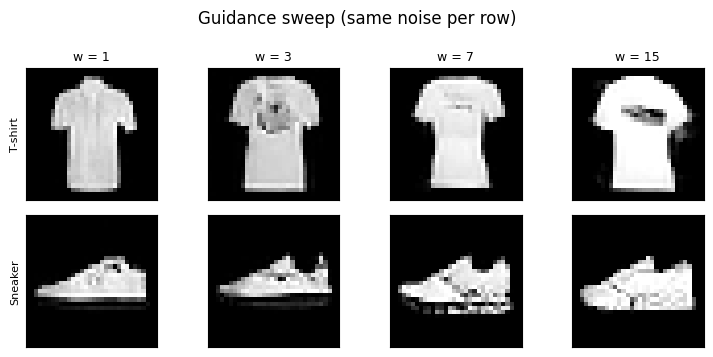

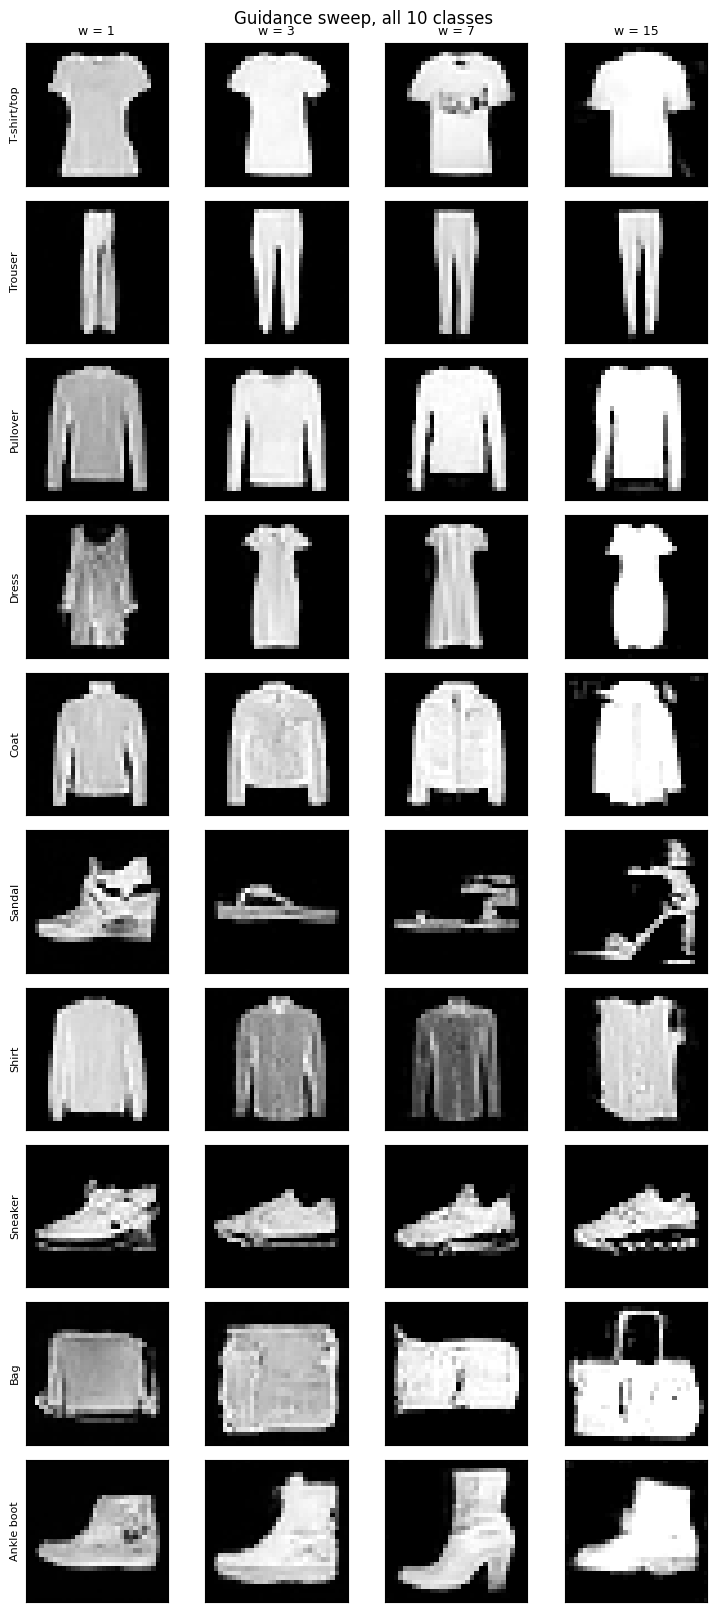

In [15]:
W_LIST = [1.0, 3.0, 7.0, 15.0]

def sweep_rows(cls, n_rows, seed):
    """Returns (n_rows, len(W_LIST), 1, 32, 32): same noise across a row."""
    z = torch.randn(n_rows, 1, 32, 32, generator=torch.Generator().manual_seed(seed)).to(DEVICE)
    y = torch.full((n_rows,), cls, device=DEVICE, dtype=torch.long)
    return torch.stack([ddpm_sample(COND_MODEL, COND_SCHED, z, y, w).cpu() for w in W_LIST], dim=1)

def plot_sweep(rows, labels, title, path):
    n = rows.size(0)
    fig, axes = plt.subplots(n, len(W_LIST), figsize=(1.6 * len(W_LIST) + 1.2, 1.6 * n + 0.4))
    axes = np.atleast_2d(axes)
    for r in range(n):
        for c, w in enumerate(W_LIST):
            axes[r, c].imshow(to01(rows[r, c])[0], cmap='gray', vmin=0, vmax=1)
            axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
            if r == 0: axes[r, c].set_title(f'w = {w:g}', fontsize=9)
        axes[r, 0].set_ylabel(labels[r], fontsize=8)
    plt.suptitle(title); plt.tight_layout(); plt.savefig(path, dpi=150, bbox_inches='tight'); plt.show()

# Required: one row of 4 images per class (classes 0 and 7) ...
req = torch.cat([sweep_rows(0, 1, seed=5), sweep_rows(7, 1, seed=6)])
plot_sweep(req, ['T-shirt', 'Sneaker'], 'Guidance sweep (same noise per row)', f'{IMG}/part2_guidance_sweep.png')
# ... plus every class, to see the trend more clearly
allc = torch.cat([sweep_rows(c, 1, seed=100 + c) for c in range(10)])
plot_sweep(allc, CLASSES, 'Guidance sweep, all 10 classes', f'{IMG}/part2_guidance_sweep_all_classes.png')

### Measuring the trade-off (numbers for the analysis)
* **Adherence** - a small CNN classifier trained on real FashionMNIST labels each generated image; adherence =
  % classified as the requested class.
* **Diversity** - mean pairwise L2 distance between generated images of the same class (higher = more varied).
  The same number for real test images is printed as a reference.
* **Saturation** - % of pixels pushed to pure black or pure white (|x| > 0.98); this rises when guidance is too strong.

In [19]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                 nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                 nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
                                 nn.Flatten(), nn.Linear(128, 10))
    def forward(self, x): return self.net(x)

clf = SmallCNN().to(DEVICE); copt = torch.optim.Adam(clf.parameters(), 1e-3)
for ep in range(1 if FAST_DEV else 3):
    clf.train()
    for x, y in loader:
        loss = F.cross_entropy(clf(x.to(DEVICE)), y.to(DEVICE)); copt.zero_grad(); loss.backward(); copt.step()
clf.eval()
test_loader = DataLoader(test_data, batch_size=500)
with torch.no_grad():
    correct = sum((clf(x.to(DEVICE)).argmax(1).cpu() == y).sum().item() for x, y in test_loader)
print(f'Classifier accuracy on real test images: {correct / len(test_data):.1%}')

def pairwise_l2(x):
    f = x.flatten(1); return torch.cdist(f, f)[~torch.eye(len(f), dtype=bool)].mean().item()

N_PER = 8 if FAST_DEV else 50
real_by_class = {c: torch.stack([test_data[i][0] for i in range(2000) if test_data[i][1] == c][:N_PER]) for c in (0, 7)}
metrics = []
for w in W_LIST:
    row = {'w': w}
    for c in (0, 7):
        x = sample_class(c, N_PER, w, seed=500 + c).cpu()
        with torch.no_grad():
            row[f'adherence_{c}'] = (clf(x.to(DEVICE)).argmax(1).cpu() == c).float().mean().item()
        row[f'diversity_{c}'] = pairwise_l2(x)
        row[f'saturation_{c}'] = (x.abs() > 0.98).float().mean().item()
    metrics.append(row); print(row)
RESULTS['part2']['sweep_metrics'] = metrics
RESULTS['part2']['real_diversity'] = {str(c): pairwise_l2(real_by_class[c]) for c in (0, 7)}
save_results()

print('\n| w | T-shirt adherence | Sneaker adherence | T-shirt diversity | Sneaker diversity | saturated px (avg) |')
print('|---|---|---|---|---|---|')
for r in metrics:
    print(f"| {r['w']:g} | {r['adherence_0']:.0%} | {r['adherence_7']:.0%} | {r['diversity_0']:.2f} | "
          f"{r['diversity_7']:.2f} | {(r['saturation_0'] + r['saturation_7']) / 2:.1%} |")
print(f"| real images | - | - | {RESULTS['part2']['real_diversity']['0']:.2f} | {RESULTS['part2']['real_diversity']['7']:.2f} | - |")

Classifier accuracy on real test images: 79.8%
{'w': 1.0, 'adherence_0': 0.8799999952316284, 'diversity_0': 16.861324310302734, 'saturation_0': 0.5408398509025574, 'adherence_7': 0.9599999785423279, 'diversity_7': 13.350013732910156, 'saturation_7': 0.7406836152076721}
{'w': 3.0, 'adherence_0': 1.0, 'diversity_0': 13.802892684936523, 'saturation_0': 0.5339453220367432, 'adherence_7': 1.0, 'diversity_7': 12.662940979003906, 'saturation_7': 0.760058581829071}
{'w': 7.0, 'adherence_0': 1.0, 'diversity_0': 12.776359558105469, 'saturation_0': 0.5654296875, 'adherence_7': 1.0, 'diversity_7': 13.014155387878418, 'saturation_7': 0.7715429663658142}
{'w': 15.0, 'adherence_0': 1.0, 'diversity_0': 13.152634620666504, 'saturation_0': 0.7479101419448853, 'adherence_7': 1.0, 'diversity_7': 14.200848579406738, 'saturation_7': 0.7967773675918579}

| w | T-shirt adherence | Sneaker adherence | T-shirt diversity | Sneaker diversity | saturated px (avg) |
|---|---|---|---|---|---|
| 1 | 88% | 96% | 16.86

### Part 2 analysis (student - about 150 words)
* What happens to **diversity** and **class adherence** as w goes 1 -> 3 -> 7 -> 15? Quote the table above.
* At which w does quality start to degrade (look at the sweep images: harsh contrast, blown-out white/black,
  repeated "average" shapes)? Why? Hint: the guided eps is an *extrapolation* past the conditional prediction,
  so at large w it leaves the range the model was trained on.

Class conditioning works: at w = 3 all five T-shirts and all five Sneakers are clearly the requested class. As w increases, class adherence goes from 88% (T-shirt) and 96% (Sneaker) at w = 1 to 100% at w = 3, 7 and 15. These come from a small classifier that is only 79.8% accurate on real images, so they are rough. T-shirt diversity falls from 16.86 at w = 1 (real images: 16.50) to 13.80 at w = 3 and 12.78 at w = 7: stronger guidance makes the samples more alike. At w = 15 diversity rises again (13.15 T-shirt, 14.20 Sneaker), but this is artefacts, not real variety.

Quality degrades at w = 15. The saturated-pixel share jumps from 66.8% (w = 7) to 77.2%; the metric also counts the black background, so the rise comes from blown-out white. In the sweep, the Dress, Coat and Shirt turn into flat white shapes with no texture and ragged edges. The guided noise eps_u + w * (eps_c - eps_u) extrapolates w times past the conditional prediction; at w = 15 it leaves the range seen in training, so every step overshoots toward pure white. w = 3 was the best trade-off in my runs.

In [20]:
save_results()
print(json.dumps(RESULTS, indent=2))
print('\nImages:'); print('\n'.join(sorted(os.listdir(IMG))))

{
  "fid_floor": 22.100335864553585,
  "part1": {
    "A_linear": {
      "fid": {
        "20": 41.59963030400786,
        "40": 36.98498252730576
      },
      "train_minutes": 20.3,
      "final_loss": 0.027844936459556095
    },
    "B_cosine": {
      "fid": {
        "20": 43.66816681300253,
        "40": 44.54780345889321
      },
      "train_minutes": 20.4,
      "final_loss": 0.050624672196104996
    },
    "C_cosine_s04": {
      "fid": {
        "20": 41.73521092483384,
        "40": 37.818212660708355
      },
      "train_minutes": 20.5,
      "final_loss": 0.045092934440089084
    }
  },
  "part1_best": "A_linear",
  "part2": {
    "schedule": "A_linear",
    "p_uncond": 0.15,
    "train_minutes": 15.2,
    "final_loss": 0.028224204103740998,
    "sweep_metrics": [
      {
        "w": 1.0,
        "adherence_0": 0.8799999952316284,
        "diversity_0": 16.861324310302734,
        "saturation_0": 0.5408398509025574,
        "adherence_7": 0.9599999785423279,
        "

---
## Submission
- [ ] `week2/homework/notebook.ipynb` (this file, with outputs)
- [ ] `week2/homework/images/` - 12 Part 1 grids, demo, guidance sweeps
- [ ] `week2/homework/memo.md` - Part 3 latency memo
- [ ] `week2/homework/README.md`
- [ ] Commit message: `Week 2 HW complete`

To download the images from Colab, run the next cell and upload `images.zip`'s contents to `week2/homework/images/`.

In [21]:
import shutil
shutil.make_archive('images', 'zip', IMG)
try:
    from google.colab import files
    files.download('images.zip'); files.download('results.json')
except ImportError:
    print('images.zip written')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>